<div style="background:linear-gradient(120deg,#EDE7FF 0%,#E3F0FF 55%,#E6FBF7 100%); color:#2A1B5C; padding:22px 26px; border-radius:14px; border:1px solid #DCD3FF; margin-bottom:8px;">

<h1 style="margin:0 0 6px 0; color:#3B1F7A">09 · Synthetic visit notes: generation, quality control and labels</h1>

<p style="margin:0 0 10px 0; font-size:1.1em; color:#4C3A8C">Level 7: using an open LLM to build the labelled dataset that real companies keep private</p>

| | |
|---|---|
| **Goal** | Create a realistic, honestly labelled dataset of sales-rep visit notes for training and evaluating our NLP models |
| **Generator** | `Qwen2.5-7B-Instruct` (open, Apache 2.0) on Google Colab's free GPU → `notebooks/colab/09a_…` |
| **Code** | `src/glp1_intel/synthetic/` (`visit_notes.py` scenarios · `gate.py` quality gate · `dataset.py` labels) |
| **Output** | `data/04_synthetic_visit_notes/visit_notes_v1.jsonl`: **1,055 notes**, clearly labelled **synthetic** |
| **Concepts** | synthetic data · grounding · labels-by-construction · few-shot prompting · sampling · rejection sampling · quality gates · diversity · BIO tagging · human validation (Cohen's κ) |

</div>

<div style="margin:6px 0 4px 0"><b>How to read this notebook:</b><br><span style="background:#F3EEFF; color:#3B1F7A; border-left:4px solid #8B5CF6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🟣 Section</span><span style="background:#FFF4E8; color:#7C2D12; border-left:4px solid #FB923C; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">💡 Concept</span><span style="background:#E9FBF8; color:#134E4A; border-left:4px solid #14B8A6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🛠️ What the next code does</span><span style="background:#EAF4FF; color:#1E3A8A; border-left:4px solid #3B82F6; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">📊 Reading the output</span><span style="background:#FFF0F3; color:#881337; border-left:4px solid #F43F5E; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">⚠️ Watch out</span><span style="background:#EAFBF1; color:#065F46; border-left:4px solid #10B981; padding:3px 10px; border-radius:6px; margin-right:6px; display:inline-block; margin-bottom:4px">🎯 Key takeaways</span></div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Why synthetic data, and what can go wrong</b>

Rep visit notes (CRM "call notes") are where field feedback lives: *"doctor worries about nausea in elderly patients, still prefers Ozempic"*. But they're **confidential**, and no company publishes them.
So we **generate** realistic ones. Synthetic data is standard practice (privacy, rare cases, bootstrapping a model), but it has well-known risks:

| Risk | What goes wrong | Our safeguard |
|---|---|---|
| **Unrealistic** | notes don't look like real field language | few-shot examples in rep style; varied styles and lengths |
| **Label noise** | the note doesn't actually express its label | **labels-by-construction** + an automatic **quality gate** + **human check** |
| **No grounding** | invented drugs, impossible side effects | scenarios sampled from **real** specialties, FAERS reactions and FDA brands |
| **Low diversity** | near-identical notes, so a model learns templates | random styles, temperature sampling, duplicate check |
| **Being mistaken for real data** | someone treats it as real evidence | "synthetic" in every file name, card and chart |

</div>

In [1]:
# ── Imports ─────────────────────────────────────────────────────────────────
import collections
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from glp1_intel import viz
from glp1_intel.viz import MUTED, TEXT, TEXT_2, subtitle
from glp1_intel.notebook_style import show
from glp1_intel.synthetic import dataset as D, gate as G, visit_notes as V

VIOLET, TEAL, PEACH = "#7C5CFF", "#0EA5A0", "#FF8A65"
scen = pd.read_json(V.SCENARIO_FILE, lines=True)
raw = pd.read_json(D.RAW_NOTES, lines=True)
data = pd.read_json(D.DATASET_JSONL, lines=True)
print(f"scenarios {len(scen):,} · generated {len(raw):,} · final dataset {len(data):,}")

scenarios 1,200 · generated 1,200 · final dataset 1,055


<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 1 · Design: labels first, text second

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Labels-by-construction and grounding</b>

Instead of generating notes and then asking someone to label them, we **decide the labels first** (a *scenario*) and ask the model to write a note that expresses them. Every note is born with its answer key.

Each scenario fixes:
- **doctor:** specialty and state, sampled from our real targeting table (segments A–E, notebook 05)
- **rep portfolio:** tirzepatide/orforglipron **or** semaglutide, chosen at random. "Competitor" is always relative to that rep, so the dataset doesn't favour one company.
- **products discussed**, **competitors mentioned**, **objections** (7 types), **interest level** (high / medium / low)
- **side-effect mode** (none / reported / negated / concern) with a term sampled from that drug's **real FAERS** reaction frequencies
- **style** (bullets, short or detailed narrative, rushed with typos) and **length**

**Consistency rules** stop contradictory scenarios, e.g. a "GI tolerability" objection forces a side-effect *concern*, and "competitor is more effective" forces a competitor mention.

</div>

In [2]:
dist = pd.concat([
    scen["rep_portfolio"].value_counts().rename_axis("value").reset_index().assign(field="rep portfolio"),
    scen["interest_level"].value_counts().rename_axis("value").reset_index().assign(field="interest level"),
    scen["ae_mode"].value_counts().rename_axis("value").reset_index().assign(field="side-effect mode"),
    scen["objections"].explode().dropna().value_counts().rename_axis("value").reset_index().assign(field="objection"),
])[["field", "value", "count"]]
show(dist, "Scenario label distributions (1,200 scenarios)")

field,value,count
rep portfolio,tirzepatide portfolio,606
rep portfolio,semaglutide portfolio,594
interest level,medium,552
interest level,high,336
interest level,low,312
side-effect mode,none,399
side-effect mode,concern,368
side-effect mode,reported,291
side-effect mode,negated,142
objection,gi_tolerability,182


In [3]:
ae = scen[scen["ae_mode"] != "none"]
show(ae["ae_term"].value_counts().head(10).rename_axis("side-effect term").reset_index(name="scenarios"),
     "Most common side-effect terms, sampled in proportion to real FAERS reports")

side-effect term,scenarios
nausea,122
constipation,84
vomiting,77
diarrhoea,56
weight increased,34
decreased appetite,30
fatigue,26
headache,25
abdominal pain,25
weight decreased,22


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- Portfolios are split ~50/50, so neither company's products are favoured.
- Side-effect terms follow **real reporting frequencies**: nausea, vomiting, diarrhoea and constipation dominate, as in FAERS. Rare-but-serious terms (pancreatitis, gallbladder) come in through the safety-concern objection.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 2 · Prompting an open model

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · System prompt, few-shot, sampling</b>

- **System message:** the role ("a rep typing a CRM note") and hard rules (no surnames, no label words, mention every brand by name).
- **Few-shot prompting:** two hand-written example notes show the *style* we want. Small and medium models copy examples much better than they follow abstract instructions.
- **Sampling:** `temperature = 0.8` and `top_p = 0.9` make each note different. Temperature rescales the probabilities (higher = more varied); top-p samples only from the most likely words covering 90% of the probability.
- **4-bit quantisation** lets a 7-billion-parameter model fit on a free 16 GB GPU.

Why an open model? It's **free**, **reproducible** (anyone can rerun it) and has a clear licence (Apache 2.0) for publishing the data.

</div>

In [4]:
prompt = json.loads(V.PROMPT_FILE.read_text())
print("SYSTEM:\n", prompt["system"], "\n")
print("EXAMPLE BRIEF:\n", prompt["few_shot"][0]["user"], "\n\nEXAMPLE NOTE:\n", prompt["few_shot"][0]["assistant"])
print("\nA REAL BRIEF FROM OUR SCENARIOS:\n", scen["brief"].iloc[3])

SYSTEM:
 You are a pharmaceutical sales rep typing a quick CRM call note right after visiting a doctor in 2026. Write ONLY the note, in plain everyday rep language (abbreviations are fine). Refer to the doctor only as 'Dr.' or 'HCP', never with a surname, and invent no other names. Never use headings or label words such as 'Attitude', 'Interest', 'Objection', 'Side effects' or 'Competitors', and never mention the word count. Show the doctor's attitude through what they said or agreed to. Mention every product and competitor named in the brief, by name, spelled correctly (if the style asks for typos, put them in ordinary words only). 

EXAMPLE BRIEF:
 Doctor: Endocrinology. Discussed: Mounjaro. Competitor: Ozempic. Doctor worries: cost, insurance coverage or prior-authorisation hassle. Attitude: positive, ready to prescribe. Side effect: one specific patient had nausea on Mounjaro. Style: short narrative. Length: about 70 words. 

EXAMPLE NOTE:
 Saw Dr. at the clinic, good convo re Moun

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 3 · The quality gate: rejection sampling

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Automatic quality control</b>

Generation is cheap; wrong labels are expensive. Every note passes through `gate.check()`, and a failing note is **regenerated** (up to 3 attempts). This is *rejection sampling*.

| Rule | Why |
|---|---|
| every product and competitor is named | otherwise product/competitor labels would be wrong |
| **no brand outside the scenario** | an extra brand silently corrupts the competitor label |
| side effect present when required (via everyday **aliases**: diarrhoea ↔ diarrhea, vomiting ↔ throwing up) | AE labels must be grounded in the text |
| **negated** side effects have a negation cue nearby; **reported** ones don't | the difference between "had nausea" and "no nausea" is the whole point |
| no leaked prompt words (`Attitude:`, "about 80 words", "no specific patient"), no headings, no surnames, no junk lines | realism and privacy |

**Interest level can't be checked by rules.** That's what the human sample (section 6) measures.

</div>

In [5]:
attempts = raw.groupby("attempt")["passed"].agg(["size", "sum"]).rename(columns={"size": "notes saved", "sum": "passed"})
display(show(attempts.reset_index(), "Colab run: on which attempt did each note pass?"))
print(f"First-try pass rate: {(raw['passed'] & (raw['attempt'] == 1)).sum() / len(raw):.0%} · "
      f"passed within 3 tries (Colab gate): {raw['passed'].mean():.0%}")

reasons = collections.Counter()
for r in raw.itertuples():
    for p in G.check(r.note, r._asdict()):
        reasons[p.split(" ")[0] + " " + p.split(" ")[1] if not p.startswith("forbidden") else "leaked prompt phrase / format"] += 1
show(pd.DataFrame(reasons.most_common(), columns=["reason (current gate)", "notes"]), "Why notes are excluded from the final dataset")

attempt,notes saved,passed
1,894,894
2,159,159
3,147,55


First-try pass rate: 74% · passed within 3 tries (Colab gate): 92%


reason (current gate),notes
leaked prompt phrase / format,82
missing competitor,43
missing side,36
reported side,15
unlisted brand,3


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- About **three quarters** of notes pass on the **first try**; regeneration rescues most of the rest.
- The most common failures are **missing a required competitor or side-effect term** and **phrases copied from the brief**: the model "forgets" part of a long instruction, exactly what a gate exists to catch.

</div>

<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Watch out · Quality gates evolve, and can over-reach</b>

The gate was **tightened after reading real output**, which is how quality control works in practice:
1. Small-model test → added a **junk-line** rule ("Rybsys / Wegy" fragments) and banned meta phrases ("no competition mentioned").
2. Reading the 7B notes → added **unlisted brand** (a note mentioning Rybelsus when no competitor was planned) and **copied-brief phrases** ("no specific patient mentioned").
3. One new rule ("side effects noted") was **too broad**: it rejected 89 notes for perfectly natural rep language ("no concerns or side effects noted"), so we **removed it**. Over-strict gates delete good data and reduce diversity.

Every rule is a trade-off between label precision and data volume, and it should be checked against real examples, never added blindly.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 4 · The final dataset

</div>

In [6]:
for mode in ["reported", "negated", "concern", "none"]:
    ex = data[data["ae_mode"] == mode].iloc[0]
    print(f"── ae_mode = {mode} · interest = {ex['interest_level']} · objections = {ex['objections']} · competitors = {ex['competitor_mentions']}")
    print(ex["note"], "\n")

── ae_mode = reported · interest = medium · objections = ['injection_aversion', 'efficacy_vs_comp'] · competitors = ['Foundayo']
- PA discussed Ozempic w/ pt for DM mgmt
- PA mentions concern: pt prefers oral over injectable
- PA notes Foundayo similar efficacy, but no direct comp study
- PA unsure, pt still on Ozempic for now
- PA: pt had constipation, adjusting dose helped
- PA: f/u in 2 wks, GI follow-up req'd 

── ae_mode = negated · interest = medium · objections = ['safety_other'] · competitors = []
Saw Dr. today. Brief visit, discussed Wegovy. Specific safety concern: pancreatitis risk. Doc unsure. Also thyroid issues, NAION, and mood changes. No mention of vomiting side effects. Open to trying but needs more data. Left some info & ask to follow up in 3 mos. Not super excited but open to it. 

── ae_mode = concern · interest = low · objections = ['gi_tolerability'] · competitors = []
- Visited Dr., fam prac
- Discussed Wegovy, Rybelsus
- Doc not sold, worried about GI issues, na

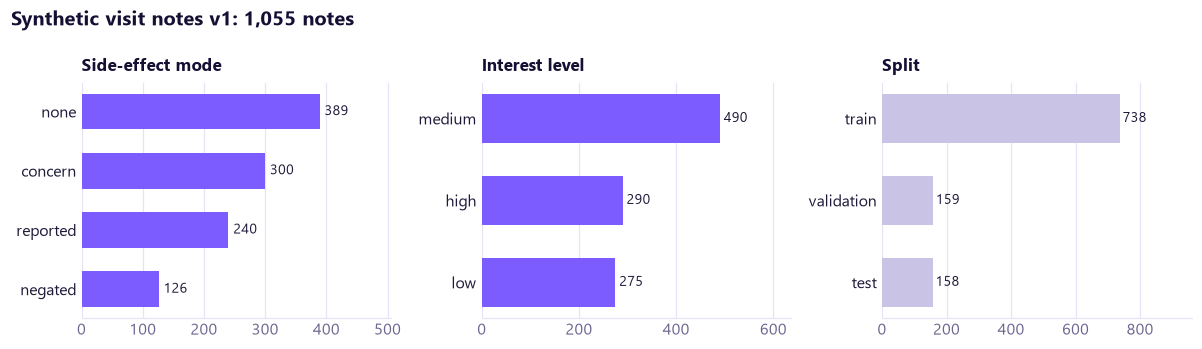

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col, title in [(axes[0], "ae_mode", "Side-effect mode"), (axes[1], "interest_level", "Interest level"),
                       (axes[2], "split", "Split")]:
    vc = data[col].value_counts()
    ax.barh(vc.index[::-1], vc.values[::-1], color=VIOLET if col != "split" else MUTED, height=0.6)
    for y, v in enumerate(vc.values[::-1]):
        ax.text(v + 8, y, f"{v:,}", va="center", fontsize=9, color=TEXT)
    ax.set_xlim(0, vc.max() * 1.3); ax.set_title(title, fontsize=11, pad=8)
fig.suptitle(f"Synthetic visit notes v1: {len(data):,} notes", x=0.01, ha="left", fontsize=13, fontweight="bold", color=viz.INK)
fig.tight_layout()
viz.save(fig, "09_1_dataset_labels")
plt.show()

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **~23% of notes report a side effect** (`ae_reported = 1`), a realistic minority, and the target of the pharmacovigilance classifier.
- **Negated** and **concern** notes are deliberately included: they contain side-effect *words* without an actual report, the hard cases that fooled the bag-of-words model in notebook 07.
- Splits are 70 / 15 / 15 (train / validation / test).

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · BIO tagging</b>

For **named-entity recognition** each word gets a tag:
- `B-DRUG` = the **B**eginning of a drug name, `I-DRUG` = **I**nside one (continuation), `O` = **O**utside any entity
- same for `ADVERSE_EVENT` and `DOSE`

Spans come from **deterministic string matching** against known lexicons (brands, generics, side-effect aliases, a dose regex), never from the generator, so every span sits exactly where its text is.

</div>

In [8]:
ex = data[data["ae_mode"] == "reported"].iloc[1]
display(show(pd.DataFrame({"token": ex["tokens"], "tag": ex["ner_tags"]}).query("tag != 'O'"), "Tagged tokens in one note (O tags hidden)"))
tags = collections.Counter(t for ts in data["ner_tags"] for t in ts)
show(pd.DataFrame([{"tag": k, "count": v} for k, v in sorted(tags.items()) if k != "O"]), "Entity tag counts across the dataset")

token,tag
Mounjaro,B-DRUG
Zepbound,B-DRUG
Mounjaro,B-DRUG
Trulicity,B-DRUG
injection,B-ADVERSE_EVENT
site,I-ADVERSE_EVENT
pain,I-ADVERSE_EVENT
Zepbound,B-DRUG


tag,count
B-ADVERSE_EVENT,984
B-DOSE,36
B-DRUG,"3,279"
I-ADVERSE_EVENT,216
I-DOSE,23


<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

Thousands of drug mentions and ~1,000 side-effect mentions give notebook 12 enough examples to train a token classifier. **Doses are rare** (~36): reps seldom write them, so DOSE will be the weakest entity type, which is honest to report.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 5 · Is the data diverse enough?

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept</b>

A classic failure of synthetic data is **template collapse**: hundreds of near-identical notes. Two quick checks:
- **Distinct-n:** share of unique word n-grams among all n-grams (higher = more varied wording)
- **Near-duplicates:** for each note, the TF-IDF cosine similarity to its most similar other note

</div>

distinct-1,distinct-2,distinct-3,median nearest-neighbour cosine,notes with a near-duplicate (cos > 0.8)
0.059,0.327,0.607,0.195,0


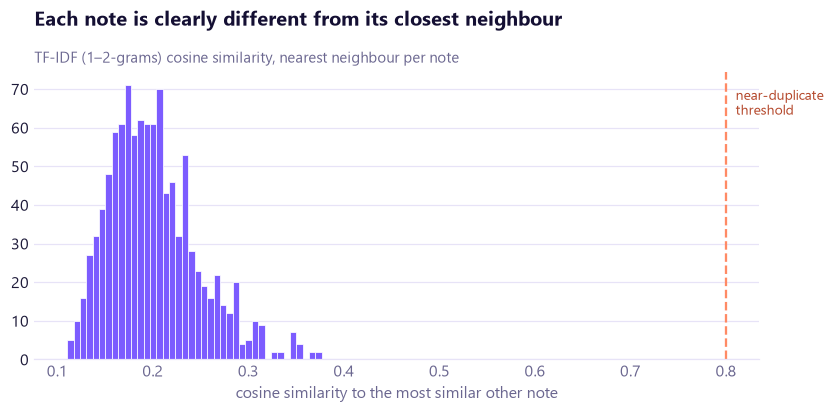

In [9]:
def distinct_n(texts, n):
    grams = [tuple(t[i:i + n]) for t in (x.lower().split() for x in texts) for i in range(len(t) - n + 1)]
    return len(set(grams)) / len(grams)

tf = TfidfVectorizer(ngram_range=(1, 2), min_df=1).fit_transform(data["note"])
sim = cosine_similarity(tf); np.fill_diagonal(sim, 0)
nearest = sim.max(axis=1)
display(show(pd.DataFrame([{"distinct-1": distinct_n(data["note"], 1), "distinct-2": distinct_n(data["note"], 2),
                    "distinct-3": distinct_n(data["note"], 3), "median nearest-neighbour cosine": np.median(nearest),
                    "notes with a near-duplicate (cos > 0.8)": int((nearest > 0.8).sum())}]),
     "Diversity checks", precision=3))

fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.hist(nearest, bins=40, color=VIOLET, edgecolor="white", linewidth=0.5)
ax.axvline(0.8, color=PEACH, lw=1.5, ls="--")
ax.text(0.81, ax.get_ylim()[1] * 0.85, "near-duplicate\nthreshold", color="#B4472A", fontsize=9)
ax.grid(axis="y"); ax.grid(axis="x", visible=False)
ax.set_xlabel("cosine similarity to the most similar other note")
ax.set_title("Each note is clearly different from its closest neighbour")
subtitle(ax, "TF-IDF (1–2-grams) cosine similarity, nearest neighbour per note")
viz.save(fig, "09_2_diversity")
plt.show()

<div style="border-left:6px solid #3B82F6; background:#EAF4FF; color:#1E3A8A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">📊 Reading the output</b>

- **No near-duplicates at all**: the most similar pair of notes is below 0.4 cosine, and the median note's closest neighbour is only ~0.20.
- **~61% of all three-word phrases are unique** (distinct-3). Notes share brand names and rep abbreviations (that's realistic) but not templates.
- These are the numbers to track if the generator, prompt or temperature ever changes.

</div>

<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 6 · Human validation: does each note match its label?

</div>

<div style="border-left:6px solid #FB923C; background:#FFF4E8; color:#7C2D12; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">💡 Concept · Inter-annotator agreement</b>

Rules can't judge **meaning** (interest level, whether a side effect is really *reported*). So a person labels a **blind** random sample of 100 test notes, without seeing the intended labels, and we measure agreement:
- **Accuracy:** % of notes where human and scenario label agree
- **Cohen's κ (kappa):** agreement corrected for chance (0 = chance, 1 = perfect; > 0.6 is usually considered substantial)

**Your task (Swagata):** open `data/04_synthetic_visit_notes/hand_label_sample_v1.csv` in Excel, fill the empty columns for each note, save it as `hand_label_done_v1.csv` in the same folder, then re-run this section.

</div>

In [10]:
done = D.DIR / "hand_label_done_v1.csv"
if not done.exists():
    print("Not labelled yet → fill hand_label_sample_v1.csv in Excel and save it as hand_label_done_v1.csv")
else:
    from sklearn.metrics import cohen_kappa_score
    h = pd.read_csv(done).merge(pd.read_csv(D.SAMPLE_KEY), on="note_id")
    rows = []
    for human, gold, name in [("interest_high_medium_low", "interest_level", "interest level"),
                              ("side_effect_reported_yes_no", "ae_reported", "side effect reported")]:
        hv = h[human].astype(str).str.strip().str.lower().replace({"yes": "1", "no": "0", "y": "1", "n": "0"})
        gv = h[gold].astype(str).str.lower()
        rows.append({"label": name, "notes": len(h), "accuracy": (hv == gv).mean(), "cohen_kappa": cohen_kappa_score(hv, gv)})
    show(pd.DataFrame(rows), "Human vs scenario labels", precision=2)

Not labelled yet → fill hand_label_sample_v1.csv in Excel and save it as hand_label_done_v1.csv


<div style="border-left:6px solid #8B5CF6; background:#F3EEFF; color:#3B1F7A; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

## 7 · Dataset card and summary

</div>

In [11]:
card = f"""# GLP-1 Rep Visit Notes (synthetic) v1

**{len(data):,} synthetic sales-representative visit notes** about US GLP-1 medicines (2026 context), each with
classification labels (interest level, objections, side-effect mode, competitor mentions) and NER spans
(DRUG, ADVERSE_EVENT, DOSE) with BIO tags. **All notes are synthetic. No real doctors, patients or reps.**

- Generator: Qwen2.5-7B-Instruct (Apache 2.0), 4-bit, temperature 0.8, few-shot prompt; labels fixed before generation
- Grounding: specialties/states from CMS Part D 2024, side-effect terms sampled from openFDA FAERS frequencies
- Quality: rule-based gate with regeneration; {raw['passed'].mean():.0%} passed within 3 attempts; final {len(data):,} after the tightened gate
- Splits: train {(data.split == 'train').sum()}, validation {(data.split == 'validation').sum()}, test {(data.split == 'test').sum()}
- Intended use: teaching and benchmarking NLP for pharma field notes (classification, NER, adverse-event flagging)
- Not for: clinical decisions, pharmacovigilance reporting, or any claim about real prescribers
- Limitations: one generator model, so its style and biases; interest level checked only on a human sample; doses rare
"""
(D.DIR / "DATASET_CARD.md").write_text(card, encoding="utf-8")
print(card)

# GLP-1 Rep Visit Notes (synthetic) v1

**1,055 synthetic sales-representative visit notes** about US GLP-1 medicines (2026 context), each with
classification labels (interest level, objections, side-effect mode, competitor mentions) and NER spans
(DRUG, ADVERSE_EVENT, DOSE) with BIO tags. **All notes are synthetic. No real doctors, patients or reps.**

- Generator: Qwen2.5-7B-Instruct (Apache 2.0), 4-bit, temperature 0.8, few-shot prompt; labels fixed before generation
- Grounding: specialties/states from CMS Part D 2024, side-effect terms sampled from openFDA FAERS frequencies
- Quality: rule-based gate with regeneration; 92% passed within 3 attempts; final 1,055 after the tightened gate
- Splits: train 738, validation 159, test 158
- Intended use: teaching and benchmarking NLP for pharma field notes (classification, NER, adverse-event flagging)
- Not for: clinical decisions, pharmacovigilance reporting, or any claim about real prescribers
- Limitations: one generator model, so its s

<div style="border-left:6px solid #F43F5E; background:#FFF0F3; color:#881337; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">⚠️ Limitations</b>

1. **One generator, one style.** A model trained only on these notes learns Qwen's way of writing; real notes are messier.
2. **Labels are only as good as their expression:** the human sample estimates how often notes really match their labels.
3. **Rule-based spans** miss unusual wording (a side effect described in words not in the lexicon).
4. **Synthetic ≠ real evidence:** insights from these notes demonstrate methods, not real doctors' opinions.

</div>

<div style="border-left:6px solid #10B981; background:#EAFBF1; color:#065F46; padding:14px 18px; border-radius:10px; margin:10px 0; box-shadow:0 1px 3px rgba(0,0,0,.06);">

<b style="font-size:1.02em; letter-spacing:.3px">🎯 Key takeaways</b>

**Done:** a published-ready, honestly documented synthetic dataset, built for ₹0 with an open model, with a reusable generate → gate → label pipeline.
**Next:** notebook 10 (how transformers work), then notebooks 11–12 fine-tune models on **this** dataset and on ADE Corpus.

**Interview questions you can now answer**
- *How do you get labelled data when real data is confidential?* Labels-by-construction synthetic data, grounded in real distributions, with a quality gate and human validation.
- *How do you control LLM-generated data quality?* Rejection sampling with explicit rules, iterated on real output, plus a blind human sample (accuracy, Cohen's κ).
- *What is few-shot prompting, and why does it help a 7B model?* Worked examples show the format and style; smaller models imitate better than they follow abstract rules.
- *Temperature vs top-p?* Temperature reshapes the whole distribution; top-p truncates it to the most likely mass, and together they control diversity.
- *What's BIO tagging?* Begin / Inside / Outside tags per token, turning span extraction into token classification.
- *How do you check synthetic data isn't repetitive?* Distinct-n and nearest-neighbour similarity.

</div>